# HW7: images, PCA and pixel inspection

**2026 edition.** Use `HW7_01.png` as image A and `HW7_02.png` as image B.
Open this notebook in Colab, run the cells in order, and upload the two PNGs
when prompted. Locally, keep them beside this notebook. No helper-file upload
is needed. Local dependencies: numpy, Pillow, matplotlib and IPython.

This starter loads the unchanged images, fits RGB PCA and extracts pixels
and horizontal five-pixel strips. It does **not** solve 9-tree addressing,
dense-cell selection, colour assignment or RP-tree / nearest-neighbour tasks.
Every example RGB listing is limited to **10 rows**, with explicit R,G,B
values and real-colour swatches. That display limit does not limit analysis.


In [16]:
from pathlib import Path
from html import escape
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import HTML, display
%matplotlib inline

IMAGE_A = Path("HW7_01.png")
IMAGE_B = Path("HW7_02.png")
PLOT_SAMPLE_SIZE = 30_000
PLOT_SEED = 2026


## Load the supplied files

The upload dialog appears only in Colab and only if a file is missing.
EXIF orientation is applied once. Pixel coordinates refer to that oriented
RGB array; the analysis input is never resized, cropped or overwritten.


In [17]:
missing = [path.name for path in (IMAGE_A, IMAGE_B) if not path.is_file()]
if missing:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Put these files beside the notebook: " + ", ".join(missing)) from None
    print("Upload the two course PNG files:", ", ".join(missing))
    files.upload()
missing = [path.name for path in (IMAGE_A, IMAGE_B) if not path.is_file()]
if missing:
    raise FileNotFoundError("Still missing: " + ", ".join(missing))


## Reusable helpers

Run this definition cell once. The notebook includes its helpers so it
also works after upload to Drive without a separate Python module.
`pixel_table`, `colour_table` and `strip_table` return HTML for
`display(HTML(...))`; each prints at most ten rows, even for huge inputs.


In [18]:
#@title Image, PCA and compact-table helpers (run once)
def load_rgb(path):
    """Apply EXIF orientation once, then return an H-by-W-by-3 uint8 array."""
    with Image.open(path) as image:
        return np.array(ImageOps.exif_transpose(image).convert("RGB"))


def _check_rgb(rgb):
    if rgb.ndim != 3 or rgb.shape[2] != 3 or rgb.dtype != np.uint8 or min(rgb.shape[:2]) < 1:
        raise ValueError("Expected a nonempty H-by-W-by-3 uint8 RGB array")


def _ids(ids, size):
    ids = np.asarray(ids)
    if ids.ndim == 1 and ids.size == 0:
        return np.empty(0, dtype=np.int64)
    if ids.ndim != 1 or not np.issubdtype(ids.dtype, np.integer):
        raise ValueError("IDs must be a one-dimensional integer array")
    if np.any(ids < 0) or np.any(ids >= size):
        raise ValueError("ID outside the image or strip collection")
    return ids.astype(np.int64, copy=False)


def fit_rgb_pca(rgb, batch_size=100_000):
    """Fit centred, unwhitened PCA to ALL pixels using a 3-by-3 covariance.

    RGB is divided by 255, not standardised per channel. NumPy's symmetric
    eigensolver supplies the principal axes. A sign convention stabilises plots.
    """
    _check_rgb(rgb)
    if batch_size < 1:
        raise ValueError("batch_size must be positive")
    pixels = rgb.reshape(-1, 3)
    reference = pixels[0].astype(np.float64) / 255
    mean = np.zeros(3)
    products = np.zeros((3, 3))
    count = 0
    for start in range(0, len(pixels), batch_size):
        block = pixels[start:start + batch_size].astype(np.float64) / 255 - reference
        block_mean = block.mean(axis=0)
        centred = block - block_mean
        delta = block_mean - mean
        new_count = count + len(block)
        # Merge centred moments; the shift also makes constant inputs exactly zero.
        products += centred.T @ centred + np.outer(delta, delta) * (count * len(block) / new_count)
        mean += delta * (len(block) / new_count)
        count = new_count
    mean += reference
    covariance = products / count
    covariance = (covariance + covariance.T) / 2
    variance, axes = np.linalg.eigh(covariance)
    order = np.argsort(variance)[::-1]
    variance = np.maximum(variance[order], 0)
    axes = axes[:, order]
    for column in range(3):
        if axes[np.argmax(np.abs(axes[:, column])), column] < 0:
            axes[:, column] *= -1
    ratio = variance / variance.sum() if variance.sum() else np.zeros(3)
    return {"mean": mean.tolist(), "axes_columns": axes.tolist(),
            "variance": variance.tolist(), "explained_fraction": ratio.tolist(),
            "scaling": "RGB/255; centred; no whitening or per-channel standardisation"}


def transform_rgb(values, model):
    """Project an N-by-3 array of original 0..255 RGB values."""
    values = np.asarray(values)
    if values.ndim != 2 or values.shape[1] != 3:
        raise ValueError("Expected an N-by-3 array")
    return (values.astype(np.float64) / 255 - model["mean"]) @ np.asarray(model["axes_columns"])


def strip_count(rgb):
    _check_rgb(rgb)
    if rgb.shape[1] < 5:
        raise ValueError("Five-pixel strips require an image at least five pixels wide")
    return rgb.shape[0] * (rgb.shape[1] - 4)


def strip_xy(rgb, ids):
    """Return x,y arrays for compact row-major strip IDs, not pixel IDs."""
    ids = _ids(ids, strip_count(rgb))
    return ids % (rgb.shape[1] - 4), ids // (rgb.shape[1] - 4)


def strip_vectors(rgb, ids):
    """Return N-by-15 float64 RGB/255, ordered R0,G0,B0,...,R4,G4,B4."""
    x, y = strip_xy(rgb, ids)
    values = rgb[y[:, None], x[:, None] + np.arange(5)]
    return values.reshape(-1, 15).astype(np.float64) / 255


def iter_strips(rgb, batch_size=50_000):
    """Yield (IDs, vectors) for all overlapping row-local strips in batches."""
    count = strip_count(rgb)
    if batch_size < 1:
        raise ValueError("batch_size must be positive")
    for start in range(0, count, batch_size):
        ids = np.arange(start, min(start + batch_size, count))
        yield ids, strip_vectors(rgb, ids)


def sample_strips(rgb, count=50_000, seed=7):
    """Sample starts without replacement, preserving duplicate colour vectors."""
    total = strip_count(rgb)
    if count < 1:
        raise ValueError("count must be positive")
    if count >= total:
        ids = np.arange(total)
    else:
        ids = np.sort(np.random.default_rng(seed).choice(total, count, replace=False))
    return ids, strip_vectors(rgb, ids)


def example_ids(size, ids=None, selection="first", seed=7):
    """Choose at most TEN rows for display; this does not sample an analysis."""
    if selection not in ("first", "random"):
        raise ValueError("selection must be 'first' or 'random'")
    if not isinstance(size, (int, np.integer)) or size < 0:
        raise ValueError("size must be a nonnegative integer")
    candidates = None if ids is None else _ids(ids, size)
    count = size if candidates is None else len(candidates)
    take = min(10, count)
    if selection == "first":
        positions = np.arange(take)
    else:
        positions = np.sort(np.random.default_rng(seed).choice(count, take, replace=False))
    return positions if candidates is None else candidates[positions]


def pixel_ids_from_xy(rgb, xy):
    """Convert supplied integer (x,y) pairs to row-major pixel IDs."""
    _check_rgb(rgb)
    xy = np.asarray(xy)
    if xy.size == 0:
        return np.empty(0, dtype=np.int64)
    if xy.ndim != 2 or xy.shape[1] != 2 or not np.issubdtype(xy.dtype, np.integer):
        raise ValueError("Expected integer (x,y) pairs")
    height, width = rgb.shape[:2]
    if np.any(xy < 0) or np.any(xy[:, 0] >= width) or np.any(xy[:, 1] >= height):
        raise ValueError("Pixel coordinate outside the image")
    return xy[:, 1].astype(np.int64) * width + xy[:, 0]


def _swatch(colour):
    red, green, blue = map(int, colour)
    label = f"RGB({red}, {green}, {blue})"
    return (f'<span role="img" aria-label="{label}" title="{label}" '
            f'style="display:inline-block;width:46px;height:22px;border:1px solid #555;'
            f'vertical-align:middle;background:rgb({red},{green},{blue})"></span>')


def _example_table(headers, rows, count, selection):
    caption = f"Showing {len(rows)} of {count:,} entries ({selection}); display limit: 10."
    cell_style = 'style="padding:5px 9px;border:1px solid #bbb;text-align:left"'
    heading = "".join(f"<th {cell_style}>{escape(header)}</th>" for header in headers)
    body = "".join("<tr>" + "".join(f"<td {cell_style}>{value}</td>" for value in row) + "</tr>"
                   for row in rows)
    return ('<table class="hw7-example-table" style="border-collapse:collapse;color:#111;background:white">'
            f'<caption style="text-align:left;color:inherit;padding:6px 0">{escape(caption)}</caption>'
            f"<thead><tr>{heading}</tr></thead><tbody>{body}</tbody></table>")


def pixel_table(rgb, ids=None, selection="first", seed=7):
    """HTML: pixel ID, x,y, separate R/G/B values and an actual-colour swatch."""
    _check_rgb(rgb)
    height, width = rgb.shape[:2]
    selected = example_ids(height * width, ids, selection, seed)
    rows = []
    for sid in selected:
        x, y = int(sid % width), int(sid // width)
        colour = rgb[y, x]
        rows.append([str(int(sid)), str(x), str(y), *map(lambda v: str(int(v)), colour), _swatch(colour)])
    return _example_table(["Pixel ID", "x", "y", "R", "G", "B", "Colour"], rows,
                          height * width if ids is None else len(ids), selection)


def colour_table(colours, selection="first", seed=7):
    """HTML: at most ten supplied RGB triples with swatches, without pixel IDs."""
    colours = np.asarray(colours)
    if colours.ndim != 2 or colours.shape[1] != 3 or colours.dtype != np.uint8:
        raise ValueError("Expected an N-by-3 uint8 array of RGB colours")
    selected = example_ids(len(colours), selection=selection, seed=seed)
    rows = [[str(int(i)), *map(lambda v: str(int(v)), colours[i]), _swatch(colours[i])] for i in selected]
    return _example_table(["Row", "R", "G", "B", "Colour"], rows, len(colours), selection)


def strip_table(rgb, ids=None, selection="first", seed=7):
    """HTML: at most ten strips, with each of their five RGB triples and swatches."""
    total = strip_count(rgb)
    selected = example_ids(total, ids, selection, seed)
    x, y = strip_xy(rgb, selected)
    rows = []
    for sid, xx, yy in zip(selected, x, y):
        colours = rgb[yy, xx:xx + 5]
        entries = [f"{_swatch(colour)}<br>{tuple(map(int, colour))}" for colour in colours]
        rows.append([str(int(sid)), str(int(xx)), str(int(yy)), *entries])
    return _example_table(["Strip ID", "x", "y", "Pixel 0", "Pixel 1", "Pixel 2", "Pixel 3", "Pixel 4"],
                          rows, total if ids is None else len(ids), selection)


A: HW7_01.png; 1536 x 1024; 1,572,864 pixels; 1,568,768 five-pixel strips
SHA256: 4caffdfd9bffe353cc7c79e0d111e44f3c0f20a8c0b7e3c56aed9290d87575c8
B: HW7_02.png; 1536 x 1024; 1,572,864 pixels; 1,568,768 five-pixel strips
SHA256: f641c4c2a9e1f8ee2131a43b833636c89f6b9fd4cff3c0ff15433ebc10f9fa43


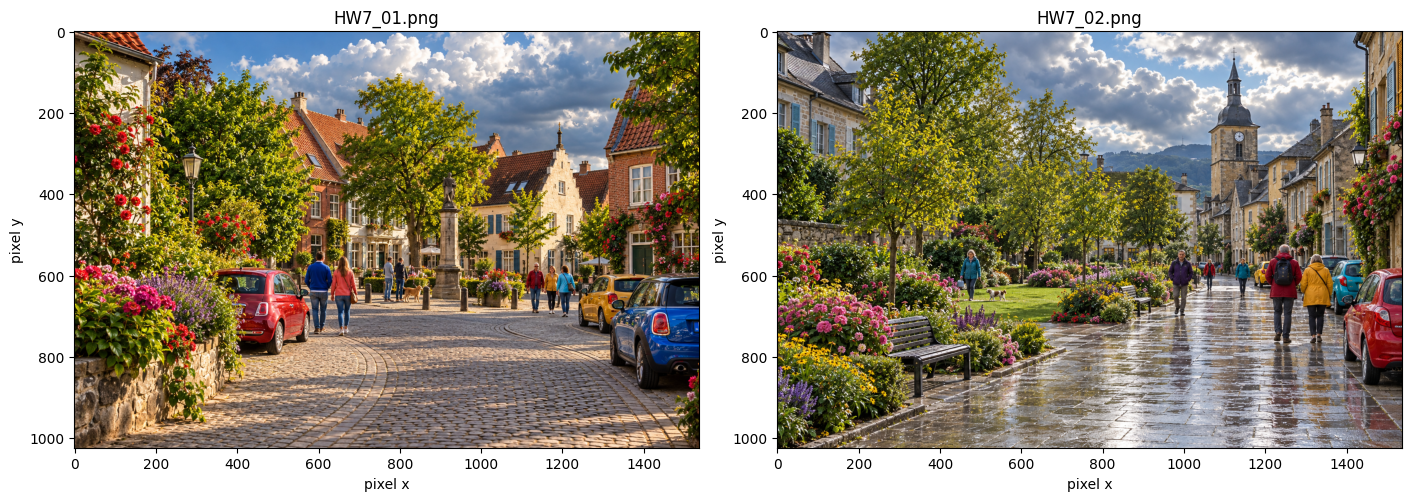

In [19]:
image_a = load_rgb(IMAGE_A)
image_b = load_rgb(IMAGE_B)
pixels_a = image_a.reshape(-1, 3)
pixels_b = image_b.reshape(-1, 3)
for label, path, image in [("A", IMAGE_A, image_a), ("B", IMAGE_B, image_b)]:
    height, width = image.shape[:2]
    with path.open("rb") as source:
        digest = hashlib.file_digest(source, "sha256").hexdigest()
    print(f"{label}: {path.name}; {width} x {height}; {width * height:,} pixels; "
          f"{strip_count(image):,} five-pixel strips")
    print("SHA256:", digest)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for ax, image, name in zip(axes, (image_a, image_b), (IMAGE_A.name, IMAGE_B.name)):
    ax.imshow(image)
    ax.set(title=name, xlabel="pixel x", ylabel="pixel y")
plt.show()


## One PCA model, three two-dimensional views

Fit **all pixels of A**, using RGB/255, centring but no per-channel scaling
or whitening. The three views use the same model: PC1-PC2, PC2-PC3, PC1-PC3.
B is transformed using **A's mean and axes**, not refitted. This keeps its
coordinates comparable; B is not required for the base homework.

Each dot retains its original RGB colour. Only the **scatter drawing** is
sampled (at most 30,000 pixels, fixed seed). `pca_a` and `pca_b` contain
**every** pixel, in row-major order. A row's pixel ID is `y * width + x`.


PC1: 82.09% of A's variance
PC2: 15.19% of A's variance
PC3: 2.72% of A's variance


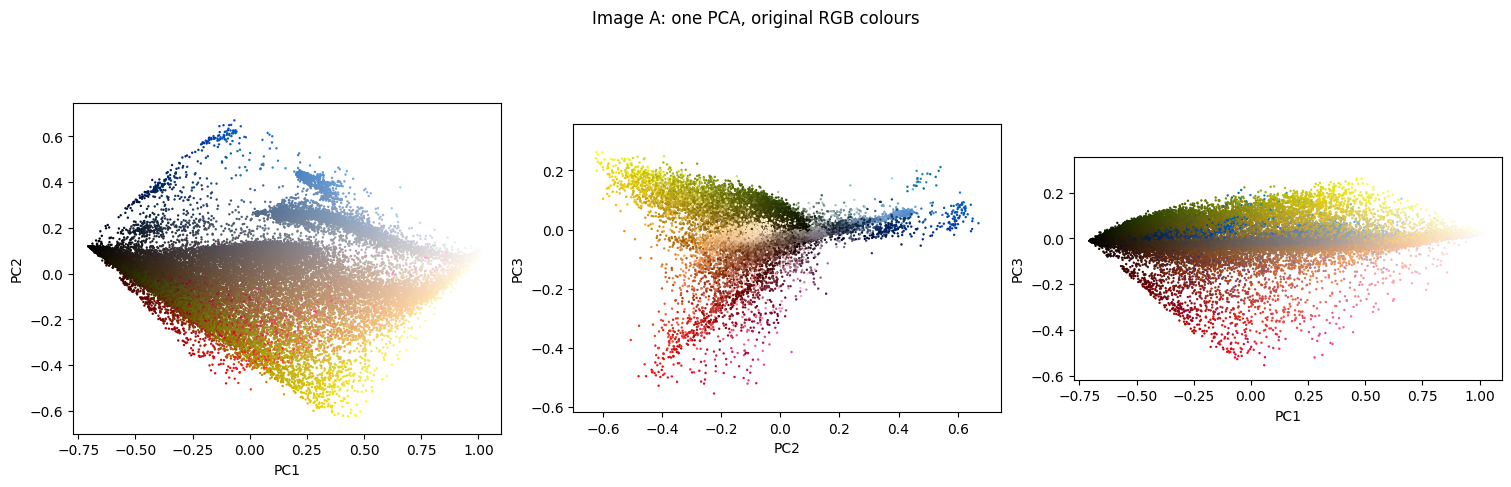

In [20]:
pca_model = fit_rgb_pca(image_a)
pca_a = transform_rgb(pixels_a, pca_model)
pca_b = transform_rgb(pixels_b, pca_model)
for i, fraction in enumerate(pca_model["explained_fraction"], 1):
    print(f"PC{i}: {100 * fraction:.2f}% of A's variance")

display_ids_a = np.sort(np.random.default_rng(PLOT_SEED).choice(
    len(pixels_a), min(PLOT_SAMPLE_SIZE, len(pixels_a)), replace=False))
display_ids_b = np.sort(np.random.default_rng(PLOT_SEED + 1).choice(
    len(pixels_b), min(PLOT_SAMPLE_SIZE, len(pixels_b)), replace=False))
pca_bounds_a = np.vstack([pca_a.min(axis=0), pca_a.max(axis=0)])
# Common drawing limits include both images. T2's boxes use A's bounds only.
plot_bounds = np.vstack([np.minimum(pca_a.min(axis=0), pca_b.min(axis=0)),
                         np.maximum(pca_a.max(axis=0), pca_b.max(axis=0))])

def plot_pca_views(scores, pixels, display_ids, title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
    colours = pixels[display_ids] / 255
    for ax, (a, b) in zip(axes, [(0, 1), (1, 2), (0, 2)]):
        ax.scatter(scores[display_ids, a], scores[display_ids, b], c=colours,
                   s=3, linewidths=0, rasterized=True)
        padding = np.maximum((plot_bounds[1] - plot_bounds[0]) * 0.04, 0.01)
        ax.set(xlabel=f"PC{a+1}", ylabel=f"PC{b+1}",
               xlim=(plot_bounds[0, a] - padding[a], plot_bounds[1, a] + padding[a]),
               ylim=(plot_bounds[0, b] - padding[b], plot_bounds[1, b] + padding[b]))
        ax.set_aspect("equal", adjustable="box")
    fig.suptitle(title)
    plt.show()

plot_pca_views(pca_a, pixels_a, display_ids_a, "Image A: one PCA, original RGB colours")


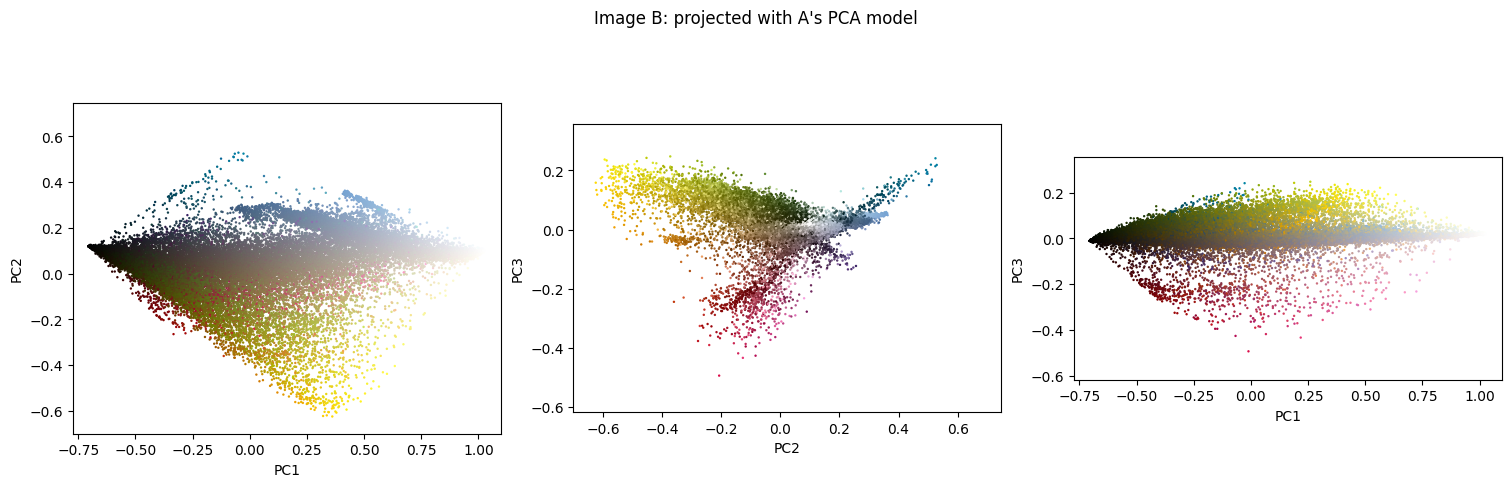

In [21]:
# Optional comparison: B projected into A's coordinate system.
plot_pca_views(pca_b, pixels_b, display_ids_b, "Image B: projected with A's PCA model")


## Inspect pixels: coordinates, R/G/B and a swatch

Default: first ten entries. `selection="random", seed=7` gives a repeatable
ten-row sample. Sampling chooses pixel locations, not distinct colours;
repeated colours remain repeated. `ids=` can be your selected cell's member
IDs, so even a cell containing thousands of pixels produces a short table.


Pixel ID,x,y,R,G,B,Colour
87343,1327,56,144,120,26,
354219,939,230,55,52,1,
472120,568,307,201,160,44,
909572,260,592,234,241,9,
983185,145,640,250,83,162,
1076117,917,700,108,107,115,
1220044,460,794,37,24,8,
1311217,1009,853,80,75,80,
1411189,1141,918,119,108,115,
1486198,886,967,125,114,125,


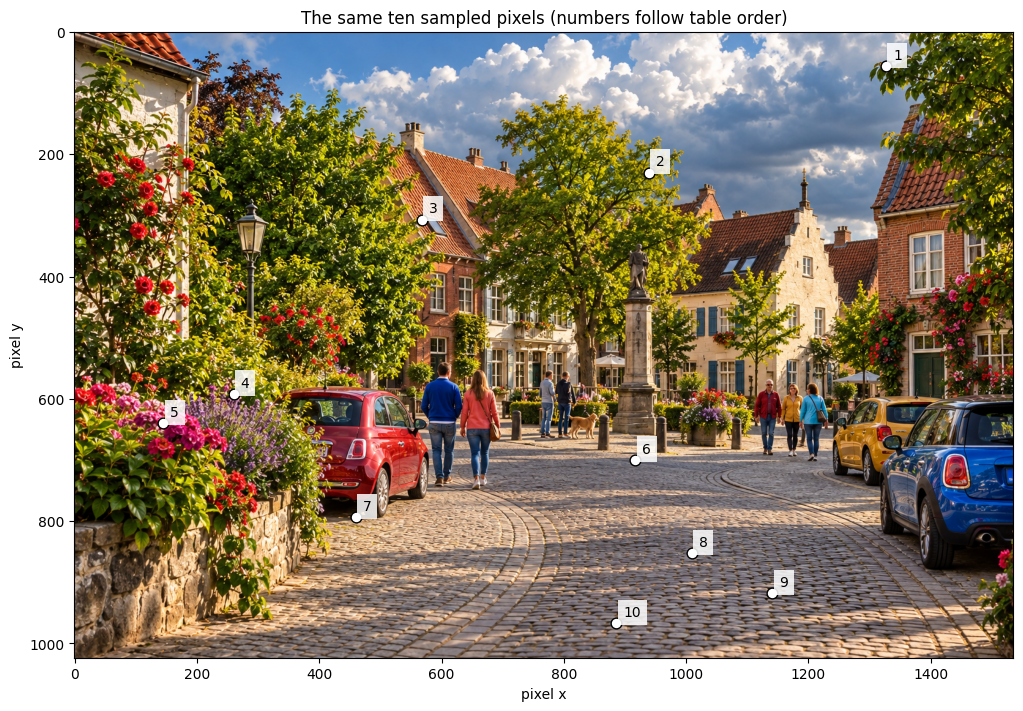

In [22]:
preview_pixel_ids = example_ids(len(pixels_a), selection="random", seed=7)
display(HTML(pixel_table(image_a, selection="random", seed=7)))

height_a, width_a = image_a.shape[:2]
fig, ax = plt.subplots(figsize=(11, 7), constrained_layout=True)
ax.imshow(image_a)
for number, sid in enumerate(preview_pixel_ids, 1):
    x, y = int(sid % width_a), int(sid // width_a)
    ax.scatter(x, y, s=60, facecolors="white", edgecolors="black")
    ax.annotate(str(number), (x, y), xytext=(5, 5), textcoords="offset points",
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85})
ax.set(title="The same ten sampled pixels (numbers follow table order)",
       xlabel="pixel x", ylabel="pixel y")
plt.show()


### Your own coordinates, IDs or RGB list

`image_a[y, x]` reads one pixel; the coordinates below are examples, not
decoded homework prefix addresses. Numeric IDs here are **row-major pixel
IDs**, not 9-tree codes. Keep the complete data in variables; only the table
display is capped. A bare notebook expression such as `pixels_a` bypasses
the table formatter, so use the functions when presenting colours.


In [23]:
chosen_xy = [(0, 0), (width_a // 2, height_a // 2), (width_a - 1, height_a - 1)]
chosen_pixel_ids = pixel_ids_from_xy(image_a, chosen_xy)
chosen_rgb = pixels_a[chosen_pixel_ids]
chosen_pca = pca_a[chosen_pixel_ids]
display(HTML(pixel_table(image_a, ids=chosen_pixel_ids)))

# Any N-by-3 uint8 RGB list: show only its first ten values, with swatches.
display(HTML(colour_table(pixels_a[:100])))
# For your T2 cell: display(HTML(pixel_table(image_a, ids=my_cell_pixel_ids)))


Pixel ID,x,y,R,G,B,Colour
0,0,0,56,36,27,
787200,768,512,114,79,33,
1572863,1535,1023,84,59,38,


Row,R,G,B,Colour
0,56,36,27,
1,46,30,23,
2,46,32,25,
3,44,31,23,
4,44,30,23,
5,46,31,24,
6,61,43,34,
7,87,65,54,
8,138,111,92,
9,199,169,140,


## Horizontal five-pixel strips: 15D data

A strip is five consecutive pixels **in one row**, flattened as
`(R0,G0,B0,...,R4,G4,B4)` and divided by 255 for calculation. Starts overlap.
There are `height * (width - 4)` strips. Strip IDs differ from pixel IDs:
`strip_id = y * (width - 4) + x`. The preview below shows three strips;
`strip_table` will never display more than ten, even with a longer ID list.


Strip ID,x,y,Pixel 0,Pixel 1,Pixel 2,Pixel 3,Pixel 4
87116,1324,56,"(156, 176, 186)","(151, 175, 171)","(152, 150, 89)","(144, 120, 26)","(190, 165, 39)"
353297,937,230,"(58, 63, 8)","(57, 62, 9)","(55, 52, 1)","(149, 142, 24)","(112, 102, 7)"
470891,567,307,"(112, 80, 13)","(201, 160, 44)","(243, 197, 58)","(181, 132, 39)","(84, 45, 14)"


Extracted vector array shape: (3, 15)


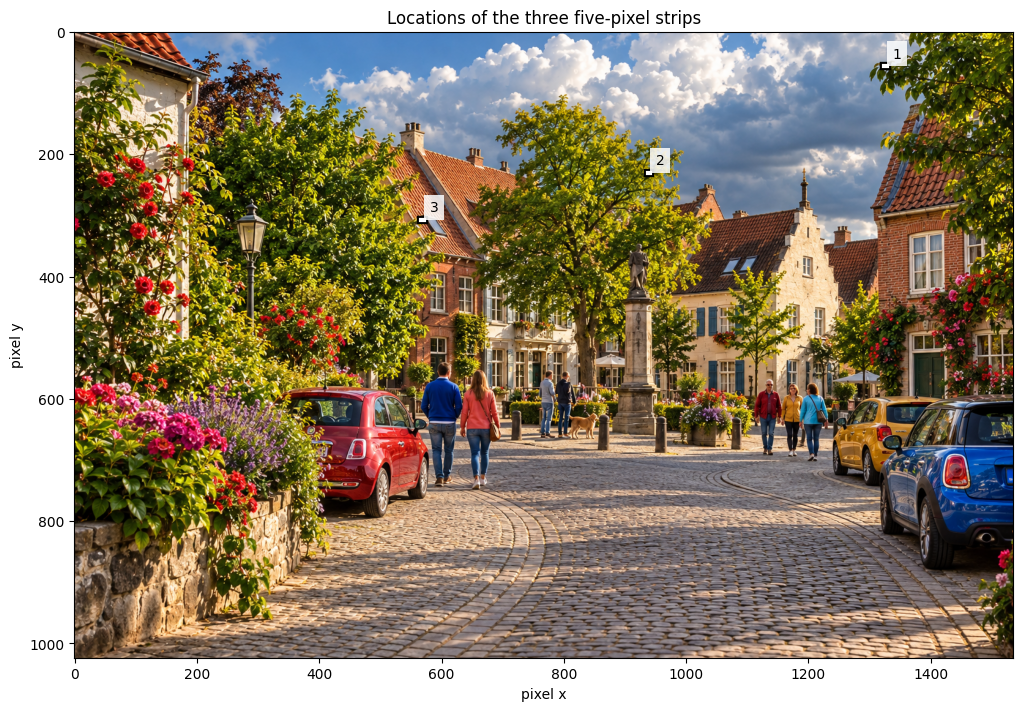

In [24]:
preview_strip_ids = example_ids(strip_count(image_a), selection="random", seed=7)[:3]
extracted_vectors = strip_vectors(image_a, preview_strip_ids)
display(HTML(strip_table(image_a, ids=preview_strip_ids)))
print("Extracted vector array shape:", extracted_vectors.shape)

strip_x, strip_y = strip_xy(image_a, preview_strip_ids)
fig, ax = plt.subplots(figsize=(11, 7), constrained_layout=True)
ax.imshow(image_a)
for number, x, y in zip(range(1, len(strip_x) + 1), strip_x, strip_y):
    ax.plot([x, x + 4], [y, y], color="black", linewidth=6)
    ax.plot([x, x + 4], [y, y], color="white", linewidth=3)
    ax.annotate(str(number), (x, y), xytext=(6, 6), textcoords="offset points",
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85})
ax.set(title="Locations of the three five-pixel strips", xlabel="pixel x", ylabel="pixel y")
plt.show()


## Use the complete data without printing it

`iter_strips` visits **all** overlapping strips in bounded batches. Put your
own T5 projection calculation inside this loop. Sampling is only for the
optional bonuses or display, never a substitute for T5's full-data counts.
These helpers leave addressing, representative selection and search to you.


In [25]:
processed = 0
for strip_ids, vectors in iter_strips(image_a, batch_size=50_000):
    # Add your calculation here; vectors has at most 50,000 rows and 15 columns.
    processed += len(strip_ids)
assert processed == strip_count(image_a)
print(f"Visited all {processed:,} strips without printing a large array.")

# Optional bonus input; these remain arrays, not output tables.
train_ids, train_vectors = sample_strips(image_a, count=50_000, seed=7)
query_ids, query_vectors = sample_strips(image_b, count=50_000, seed=8)
print("Bonus sample shapes:", train_vectors.shape, query_vectors.shape)


Visited all 1,568,768 strips without printing a large array.
Bonus sample shapes: (50000, 15) (50000, 15)


## Variables to reuse

- `image_a`, `image_b`: full oriented RGB arrays, integer values 0-255.
- `pixels_a`, `pixels_b`: row-major RGB views, one row per pixel.
- `pca_model`, `pca_a`, `pca_b`: A's fitted model and full-data coordinates.
- `pca_bounds_a`: A's min/max for each PC; use these for T2's root rectangles.
- `display_ids_a`, `display_ids_b`: fixed **plotting-only** samples.
- `pixel_table`, `colour_table`, `strip_table`: short RGB/swatch displays.
- `strip_vectors`, `iter_strips`, `sample_strips`: selected, full or sampled 15D input.

Include selected figures and a concise explanation in your report, not the
whole notebook output. A swatch is an illustration; the numeric RGB values
are the reproducible data. This is RGB-space experimentation, not calibrated
human colour perception. Image redistribution permission is handled separately.
